### Import Libraries

In [1]:
import h5py
import numpy as np
import healpy as hp
import matplotlib.pyplot as plt
from lenspack.geometry.projections.gnom import radec2xy, xy2radec
from functools import partial
from matplotlib.colors import TwoSlopeNorm
from astropy.io import fits
from lenspack.utils import bin2d
from astropy.convolution import convolve_fft, Gaussian2DKernel, Tophat2DKernel
from skimage.measure import label, regionprops
import treecorr
import os
from astropy.io import fits
from astropy import units as u
import matplotlib
# matplotlib.use('Agg')
import matplotlib.pyplot as plt
import numpy as np 
import multiprocessing
from multiprocessing import Pool
import os 
import re
import itertools
import time
import sys
import treecorr
from astropy.convolution import convolve_fft, Gaussian2DKernel, Tophat2DKernel
from lenspack.peaks import find_peaks2d, peaks_histogram
#from sheydenreich_threepoint.aperture_mass_computer_v3 import aperture_mass_computer
from lenspack.image.transforms import starlet2d
from skimage.measure import label, regionprops
from lenspack.utils import bin2d
from scipy.interpolate import griddata

### Import Projection Functions

In [2]:
# Cartesian/gnomonic projection from spherical map (about equivalent)
def get_flat_projection(proj_method, sph_map, center, side_deg, flat_nside):
    
    ''' 
        
        Important reminder: lat:[-90, +90]  long:[0, 360] deg
        
        0th. Note: healpix pixels are qaudrilateral of SAME AREA but with varying elongation (https://iopscience.iop.org/article/10.1086/427976/pdf).
                   The area of a general quadrilateral on a unitary sphere in spherical lat/long coords is https://www.johndcook.com/blog/2023/02/21/sphere-grid-area/ (area given in sterads)
                   For a fixed delta in lat/long, the area is consistent with a flat square close to the equator (lat=0), while it is will be severely affected by the curvature thus reducing towards the poles (lat=+/-90).
                   Pixels towards the poles are more elongated in order to embed the same area. 
                   That is why, when fixing the same delta on lat and long, the number of pixels contained into the given coord range reduces towards the poles. 
    
        1st. Note: flat map has a pixel resolution approximated by side_deg / flat_nside. 
                   Depending on the projection method, the effective side_deg can slightly change thus changing the effective pixel resolution.
                   'Cart' has a more accurate effective side_deg than 'Gnom'.
                   
                
        2nd. Note: the cut from spherical to cartesian cannot be perfect since:
            1) the spherical resolution is an approximation of the flat resolution,
            2) the spherical pixel geometry (polygonal) is different wrt the flat pixel geometry (square)
            
        3rd. Note: The projection algorithm takes as inputs side_deg and flat_nside defining a physical binning (arcmins) from which projecting the spherical pixels.
                   side_deg defines the proper angular size of the final flat map and not the range of spherical coordinates from which operate the projection!
                   Given side_deg, the algorithm will spot the quadrilateral on the sphere centered on the provided central point such that its area is equal to side_deg^2, and then projecting it into a cartesian grid.
                   If the ratio side_deg/flat_nside is lower wrt the spherical pixel size, the projected map will contain replicated pixels!
                   It is safer to select side_deg, flat_nside for which side_deg/flat_nside is equal to the spherical pixel size.
    
        4th. Note: proj_Cart.projmap returns a Cartesian map in matricial convention: (i, j) = (row, col) = (long, lat) = (ra, dec) where (0,0) element is the lower-left-corner (e.g. projecting a 10x10 sq.deg map w/ centre in long, lat = 5, 5 deg, map[0,0] will correspond to a 45 degrees rotation of long=10, lat=0)
                   To match the visual convention (long-ra on y-axis, lat-dec on x-axis) one should transpose the map
    
    '''

    ''' Cartesian grid must be clockwise/counterclockwise rotated by 45deg (in this case, we opted for clockwise rotation) in order to be aligned with the Healpix grid '''
    psi = +45 # positive psi = clockwise
    center = (center[0], center[1], psi)

    if proj_method == 'Cart':
        
        angle = side_deg / 2
        angular_size = [-angle, angle] # effective FoV of projected map
        proj_Cart = hp.projector.CartesianProj(rot=center, coord=["G"], xsize=flat_nside,
        ysize=flat_nside, lonra=angular_size, latra=angular_size)
        map_flat = proj_Cart.projmap(sph_map, vec2pix_func=partial(hp.vec2pix, hp.
        get_nside(sph_map)))
    
    if proj_method == 'Gnom':
        
        fig_gnom, ax = plt.subplots(1,1)
        map_flat = hp.gnomview(sph_map, rot=center, coord=["G"], reso=hp.nside2resol(hp.get_nside(sph_map), arcmin=True), xsize=flat_nside, return_projected_map=True, cmap='bwr', nest=False, fig=fig_gnom)
        plt.close(fig_gnom)
        
    return map_flat


##----------------------------------------------------------------------------## 


# Defines central points on sphere from which projecting a flat map
def generate_subpatch_central_points(side_deg):
    
    '''
    
    Note: the following central points depend only on the angular aperture of the final projected flat map (flat_nside) and not on the spherical nside (sph_nside)!
          Of course, higher the spherical nside and higher the accuracy of the projected flat maps!
    
    Note: The following algorithm is based on a flat geometry approximation. So it is accurate for small enough latitudes.
          It means that we are assuming to produce flat square patches from  spherical coords of central points +/- deg_side/2.
          As we know, moving at higher latitudes, the area embedded into central points +/- deg_side/2 will be lower than expected in a flat case because of the curvature.
          The proper spherical coords ranges corresponding to the projected flat patches -with area side_deg^2- will be wider because of the curvature.
          For the same reason, the assumed separation (3 deg) between the flat patches reduces at higher latitudes since we are not taking into account the widening of the spherical coords ranges of the projected flat maps.
    
    Note: the projection effects are minimized towards the equator (lat=0).
          It is worth to reduce the latitude domain close to the equator (lat = +/- 20 deg).
          Infact, the area of a spherical sub-patch for a given delta_lat, delta_lon reduces towards the poles!
          
    Note: the sub-patches are separated by 3 deg in both lat and lon to avoid overlappings in the final flat patches (it seems to be a good value for several low nside's, found by hand)
    
    Note: longitude domain is narrowed down by a constant factor 0.5*side_deg to avoid extremal points transitions
    
    '''
    
    longitudes = []
    latitudes = []
    patches_separation = 3 # deg
    
    # Generate central points
    for lon in np.linspace(0 + 0.5*side_deg + 0.5*patches_separation, 360 - 0.5*side_deg - 0.5*patches_separation, num=int((360-side_deg)/(side_deg + patches_separation)), endpoint=True):
        for lat in np.arange(-20, 20, side_deg + patches_separation):
            
            longitudes.append(lon)
            latitudes.append(lat)
            
    print(f'Total selected independent flat sub-patches: {len(longitudes)}')
    
    return list(zip(longitudes, latitudes))


##----------------------------------------------------------------------------## 


# Rotation matrix function
def rotator_2D(x, y, angle, x_shift=0, y_shift=0, units="DEGREES"):
    
    import math 
    
    """
    
    FUNDAMENTAL NOTE: rotator_2D() and rot() in get_flat_projection() follow same rotational convention (clockwise rotation if angle is positive)
    
    Rotates a point in the xy-plane counterclockwise through an angle wrt a central point [x_shift, y_shift] (aka origin if [0,0])
    https://en.wikipedia.org/wiki/Rotation_matrix
    :param x: x coordinate
    :param y: y coordinate
    :param x_shift: x-axis shift from origin (0, 0)
    :param y_shift: y-axis shift from origin (0, 0)
    :param angle: The rotation angle in degrees between [angle >/< 0 clockwise/counterclockwise]
    :param units: DEGREES (default) or RADIANS
    :return: Tuple of rotated x and y
    """

    # Shift to origin (0,0)
    x = x - x_shift
    y = y - y_shift

    # Convert degrees to radians
    if units == "DEGREES":
        angle = math.radians(angle)

    # Rotation matrix multiplication to get rotated x & y
    xr = (x * math.cos(angle)) - (y * math.sin(angle)) + x_shift
    yr = (x * math.sin(angle)) + (y * math.cos(angle)) + y_shift

    return xr, yr

### Load GLASS map and extract mean Cosmo-SLICS n(z)

sph_nside 2048, res 1.717743205908703 arcmins


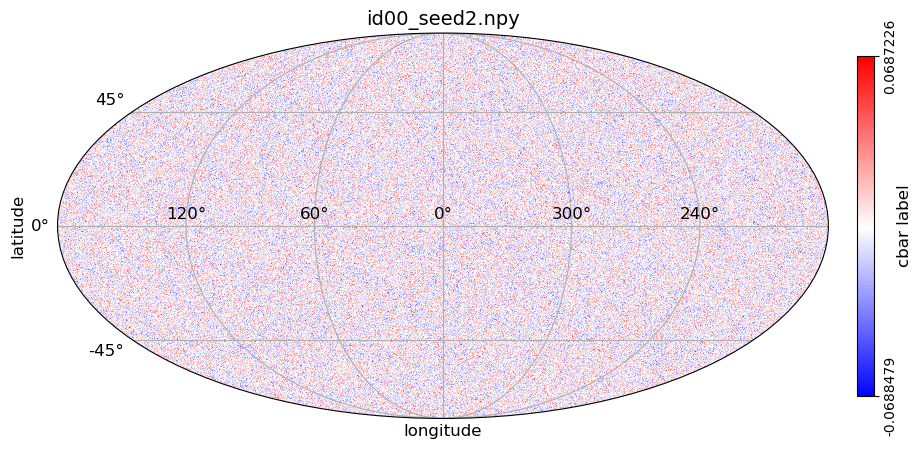

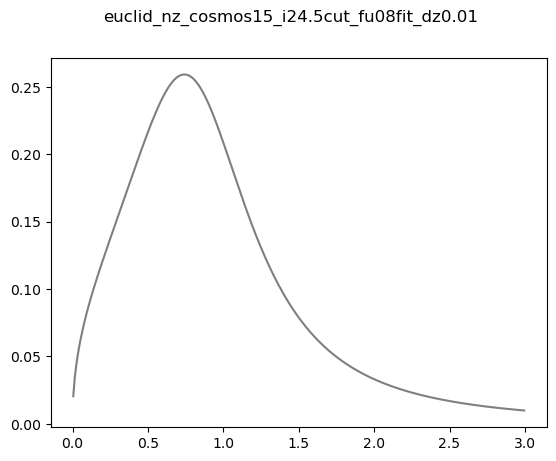

In [18]:
# Define simulation path
inpath = ''
sims_path = '/net/GECO/pisco/SHEAR2COSMO/Leo_COSMO-SLICS/data/GLASS_maps/spherical/'
field_type = 'gaussian' #'gaussian', 'lognorm'
lognorm_shift = None
seed = 0 # GLASS-seed 
sim_fname = f'glass_{field_type}_kappa_COSMOSLICS_0_euclid_nz_cosmos15_i24.5cut_fu08fit_dz0.01_nside_2048_lmax_5120_zmax_3.0_hpwindowfunction_0_seed_{seed}' # [kappa]

# Load GLASS spherical map [nested ordering, NOT ring]
map_name = 'id00_seed2.npy' 
sph_map_path = f'/net/GECO/pisco/SHEAR2COSMO/DBB_OPT_52/spherical/'
sph_map = np.load(sph_map_path+map_name)

# # Downgrade healpix map to 1/2 of original sph_nside (if needed)
# sph_nside = hp.pixelfunc.get_nside(sph_map)
# sph_map = hp.pixelfunc.ud_grade(map_in=sph_map, nside_out=int(sph_nside/2), order_in='RING')

# Extract GLASS spherical map properties
sph_nside = hp.pixelfunc.get_nside(sph_map)
map_res_sph = hp.pixelfunc.nside2resol(sph_nside, arcmin=True)
print(f'sph_nside {sph_nside}, res {map_res_sph} arcmins')

# Plot GLASS spherical map
hp.projview(
    sph_map,
    xsize=2000,
    coord=["G"],
    graticule=True,
    graticule_labels=True,
    unit="cbar label",
    xlabel="longitude",
    ylabel="latitude",
    cb_orientation="vertical",
    cmap='bwr',
    latitude_grid_spacing=45,
    projection_type="mollweide",
    nest=False,
    title=f"{map_name}",
);

# Plot n(z) 
nz_inpath = '/net/GECO/pisco/SHEAR2COSMO/Leo_COSMO-SLICS/data/nz/'
nz_fname = 'euclid_nz_cosmos15_i24.5cut_fu08fit_dz0.01'
z_midp, nz = np.genfromtxt(nz_inpath + f'{nz_fname}.cat', unpack=True)
cosmoslics_ngal = 30.0 #gal/arcmin^2

fig_nz, ax_nz = plt.subplots(1, 1, squeeze=False)
ax_nz[0,0].plot(z_midp, nz, alpha=0.5, color='black')  
# ax_nz[0,0].set_xscale('log')
# ax_nz[0,0].set_yscale('log')
fig_nz.suptitle(f'{nz_fname}')
fig_nz.savefig(nz_inpath + f'{nz_fname}.png', dpi=300)
fig_nz.show()

### Divide full-sky into independent flat-patches where the projection effects are reasonable

Total selected independent flat sub-patches: 104


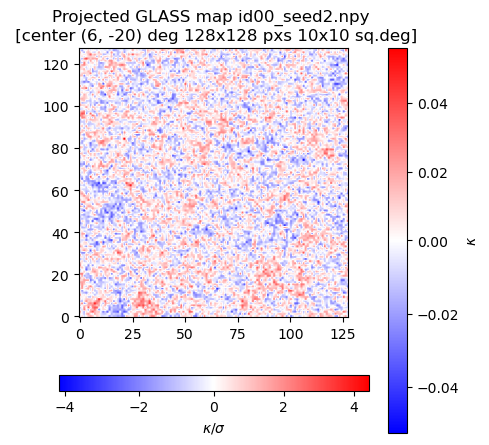

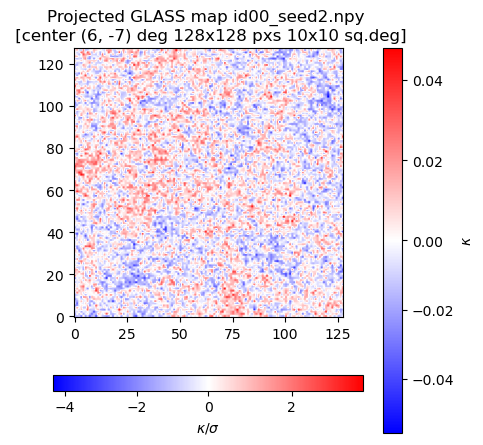

In [19]:
# Define properties of the final flat map computing the effective flat map resolution given side_deg and map_res_sph
''' Note: Since the number of total pixels per side in the flat map is an integer, the effective flat map resolution will be slightly different from the spherical one! '''
sph_nside = hp.pixelfunc.get_nside(sph_map)
map_res_sph = hp.pixelfunc.nside2resol(sph_nside, arcmin=True)
side_deg = 10 # map side in deg
nside = 128 #int(side_deg / (map_res_sph / 60))  # number of pixels per map side
flat_nside = nside
map_res = 60 * side_deg / nside # map side in arcmins

'''
Note: The spherical splitting into flat sub-patches is defined only by side_deg and not by sph_nside.
      Of course, higher the spherical map resolution (sph_nside) and higher the accuracy of the projected flat maps!
'''

# Divide full-sky into N flat sub-patches where projection effects are limited (lat +/- 30 deg)
central_points = generate_subpatch_central_points(side_deg) # central points
map_cuts = np.empty((len(central_points), flat_nside, flat_nside))

for ind, square_subpatch_center_coords in enumerate(central_points): # centre sub-patch coords as lon (x-axis), lat (y-axis) in degrees
   
    # Rebinning directly during the projection (best)
    map_cuts[ind] = get_flat_projection('Cart', sph_map, [square_subpatch_center_coords[0], square_subpatch_center_coords[1]], side_deg, flat_nside)
    
    # Remove decimals from pointing-coords
    square_subpatch_center_coords = (int(square_subpatch_center_coords[0]), int(square_subpatch_center_coords[1]))
    
    # Save projected map
    map_outpath = '/net/GECO/pisco/SHEAR2COSMO/Leo_COSMO-SLICS/data/GLASS_maps/spherical_to_cartesian/'
    #np.save(map_outpath + f'{sim_fname}_cartesian_proj_LOS_{ind}_center_{square_subpatch_center_coords}deg_npix_{map_cuts[ind].shape[0]}px_degside_{side_deg}deg' + '.npy', map_cuts[ind])

    # Plot COSMO-SLICS kappa map and GLASS map
    if ind < 2:
        
        fig, ax = plt.subplots(1,1, figsize=(5,5), squeeze=False)
        ax[0,0].set_title(f'Projected GLASS map {map_name} \n [center {square_subpatch_center_coords} deg {map_cuts[ind].shape[0]}x{map_cuts[ind].shape[1]} pxs {side_deg}x{side_deg} sq.deg]')
        norm = TwoSlopeNorm(vmin=(map_cuts[ind]).min(), vcenter=0, vmax=(map_cuts[ind]).max())
        mappable = ax[0,0].imshow(map_cuts[ind], cmap='bwr', origin='lower', norm=norm)
        cbar = fig.colorbar(mappable, ax=ax[0,0], orientation='vertical', label=f'$\kappa$')
        norm = TwoSlopeNorm(vmin=(map_cuts[ind]/np.std(map_cuts[ind])).min(), vcenter=0, vmax=(map_cuts[ind]/np.std(map_cuts[ind])).max())
        mappable = ax[0,0].imshow(map_cuts[ind]/np.std(map_cuts[ind]), cmap='bwr', origin='lower', norm=norm)
        cbar = fig.colorbar(mappable, ax=ax[0,0], orientation='horizontal', label=f'$\kappa / \sigma$')
        #fig.savefig(map_outpath + f'{sim_fname}_cartesian_proj_LOS_{ind}_center_{square_subpatch_center_coords}deg_npix_{map_cuts[ind].shape[0]}px_degside_{side_deg}deg' + '.png', dpi=300)
        fig.show()
